In [1]:
%pip install yfinance pandas

In [2]:
import yfinance as yf
import pandas as pd

# Extract Tesla stock data
tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(period="max")

# Reset the index
tesla_data.reset_index(inplace=True)

# Display the first five rows
display(tesla_data.head())

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [3]:
%pip install pandas requests beautifulsoup4 lxml

In [5]:
# Question 2: Use Webscraping to Extract Tesla Revenue Data

import pandas as pd
import requests
from bs4 import BeautifulSoup
from io import StringIO

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

response = requests.get(url, timeout=30)
response.raise_for_status()


soup = BeautifulSoup(response.text, "html.parser")


tables = pd.read_html(StringIO(str(soup)))

tesla_revenue = None

for table in tables:
    if table.shape[1] >= 2:
        first_column = table.iloc[:, 0].astype(str)
        if first_column.str.contains(r"\d{4}-\d{2}-\d{2}", regex=True).any():
            tesla_revenue = table.iloc[:, :2].copy()
            break

if tesla_revenue is None:
    raise ValueError("Tesla revenue table was not found on the webpage.")


tesla_revenue.columns = ["Date", "Revenue"]

tesla_revenue["Revenue"] = (
    tesla_revenue["Revenue"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)


tesla_revenue = tesla_revenue[
    tesla_revenue["Revenue"].ne("")
    & tesla_revenue["Revenue"].ne("nan")
].copy()

tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


In [6]:
import yfinance as yf
import pandas as pd


gme = yf.Ticker("GME")
gme_data = gme.history(period="max")


gme_data.reset_index(inplace=True)

print("GameStop Stock Data - First Five Rows:")
display(gme_data.head())

GameStop Stock Data - First Five Rows:


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693349,1.603295,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683251,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658001,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615921,1.662210,1.603296,1.662210,6892800,0.0,0.0


In [9]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
from io import StringIO

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

html_data = requests.get(url).text
soup = BeautifulSoup(html_data, "html.parser")

tables = pd.read_html(StringIO(str(soup)))

gme_revenue = tables[1]
gme_revenue.columns = ["Date", "Revenue"]

gme_revenue["Revenue"] = (
    gme_revenue["Revenue"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

gme_revenue.dropna(inplace=True)


gme_revenue.tail()

,Date,Revenue
49,2010-06-30,28
50,2010-03-31,21
51,2009-12-31,nan
52,2009-09-30,46
53,2009-06-30,27


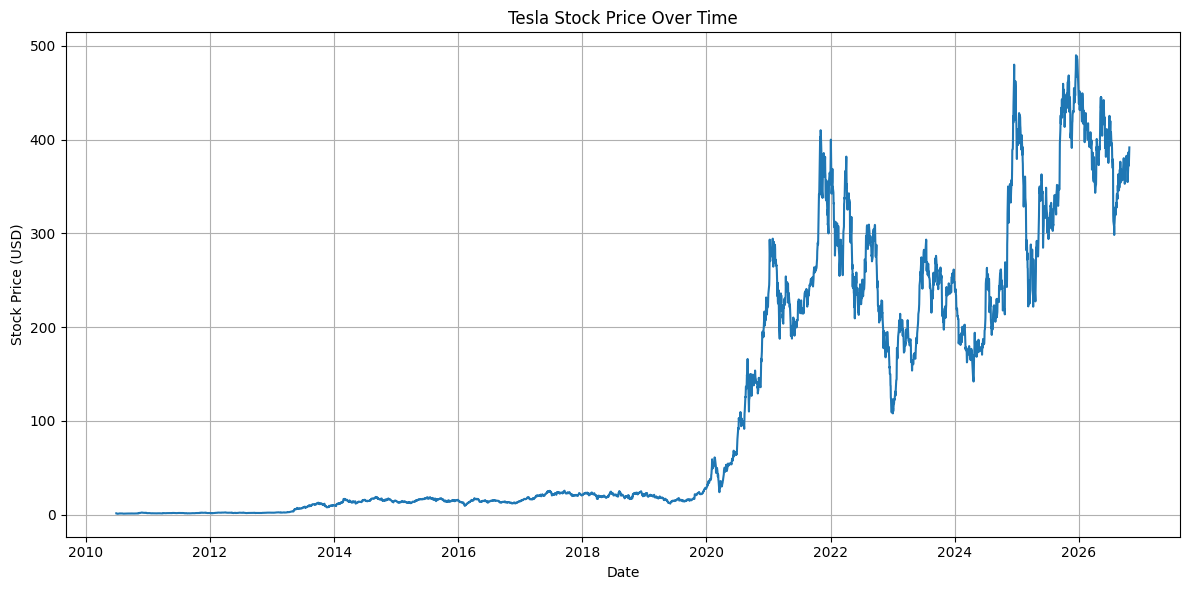

In [10]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(period="max")
tesla_data.reset_index(inplace=True)

def make_graph(stock_data, stock):
    plt.figure(figsize=(12, 6))
    plt.plot(stock_data["Date"], stock_data["Close"])
    plt.title(f"{stock} Stock Price Over Time")
    plt.xlabel("Date")
    plt.ylabel("Stock Price (USD)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

make_graph(tesla_data, "Tesla")

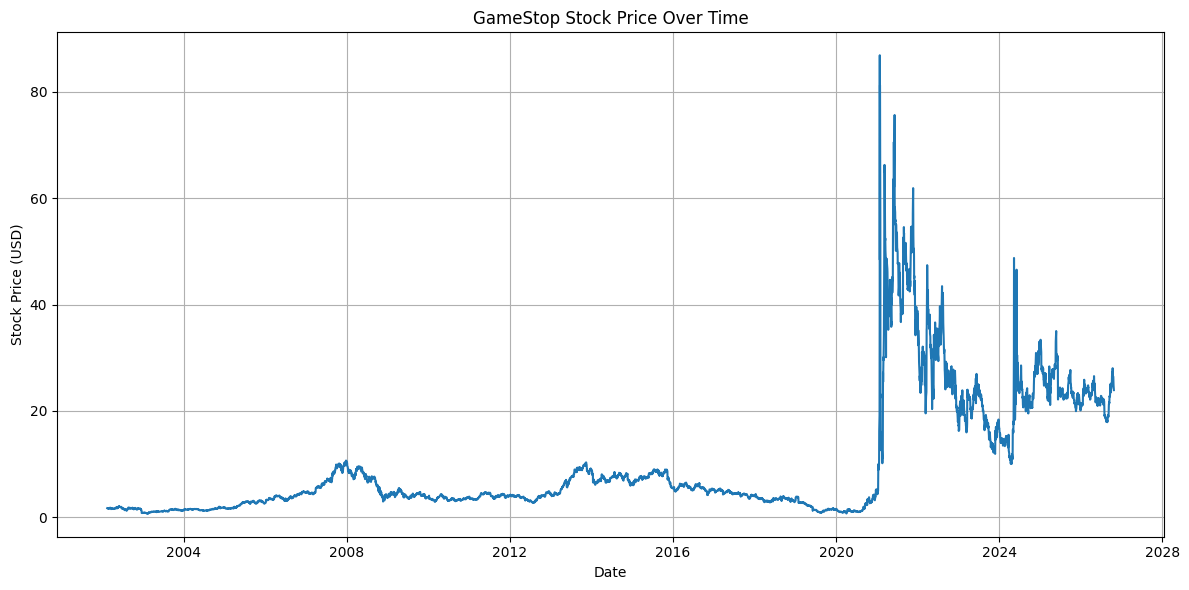

In [11]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

gme = yf.Ticker("GME")
gme_data = gme.history(period="max")
gme_data.reset_index(inplace=True)

def make_graph(stock_data, stock):
    plt.figure(figsize=(12, 6))
    plt.plot(stock_data["Date"], stock_data["Close"])
    plt.title(f"{stock} Stock Price Over Time")
    plt.xlabel("Date")
    plt.ylabel("Stock Price (USD)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

make_graph(gme_data, "GameStop")